# 📊 EDA del COVID-19 en EE. UU. · COVID Tracking Project

**Contexto.** Somos el equipo de datos de una consultora. El CEO de un cliente nos entrega un conjunto de datos que nadie ha mirado con calma y nos pide tres cosas: datos **limpios**, que tengan **sentido**, y la **historia** que hay detrás, antes de decidir qué hacer con ellos.

**Datos.** [COVID Tracking Project](https://covidtracking.com/), endpoint `states/daily` (`https://api.covidtracking.com/v1/states/daily.csv`): una fila por estado y día con casos, pruebas, hospitalizaciones y fallecimientos. Cubre del 13-ene-2020 al 7-mar-2021. Como **segunda fuente** usamos la población de cada estado (estimación del Census 2019) para comparar con justicia.

## Preguntas que nos planteamos antes de mirar los datos

1. **P1.** ¿Cuándo fueron los peores momentos a nivel nacional y cuánto se parecieron entre sí?
2. **P2.** ¿Qué estados sufrieron más cuando se comparan de forma justa, por cada 100.000 habitantes?
3. **P3.** ¿Los estados que hicieron más pruebas detectaron más casos?
4. **P4.** ¿Cambió la letalidad aparente (muertes ÷ casos) con el tiempo? ¿Depende del tamaño del estado?
5. **P5.** ¿Qué tan fiables son los datos, y cambian las conclusiones por sus problemas de calidad?

Las respondemos por escrito en la sección 11.

## Cómo está organizado

`1` Carga · `2` Limpieza justificada · `3` Segunda fuente y variables nuevas · `4` Univariado · `5` Atípicos · `6` Bivariado · `7` Agrupar y resumir · `8` Correlaciones · `9` Tendencias · `10` Comparar segmentos · `11` Gráficos interactivos · `12` Respuestas · `13` Conclusiones.

> La lógica de limpieza vive en `src/clean_data.py` y `src/build_features.py` (con tests en `tests/`). Aquí la usamos paso a paso para explicar cada decisión.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter

warnings.filterwarnings("ignore")

# El notebook funciona tanto desde la raíz del repo como desde notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import build_features, clean_data

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda v: f"{v:,.0f}" if float(v).is_integer() else f"{v:,.2f}")

# Paleta validada (azul, naranja, verde agua, amarillo) + tintas neutras
AZUL, NARANJA, AGUA, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SEQ = LinearSegmentedColormap.from_list("seq", ["#dce9fa", AZUL, "#12396b"])   # magnitud
DIV = LinearSegmentedColormap.from_list("div", [NARANJA, "#ecebe8", AZUL])      # polaridad
AZULES4 = ["#a9c7ef", "#6aa0e3", AZUL, "#12396b"]                              # categorías ordenadas

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "font.size": 10,
})

def guardar(fig, nombre):
    fig.savefig(FIG / nombre, dpi=150, bbox_inches="tight", facecolor="white")

def coma(v, nd=1):
    # decimales con coma para los textos en español
    return f"{v:.{nd}f}".replace(".", ",")

def miles(ax, eje="y"):
    # separador de miles con punto en el eje indicado
    f = FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", "."))
    (ax.yaxis if eje == "y" else ax.xaxis).set_major_formatter(f)

def etiquetas_finales(ax, xs, ys, nombres, hueco):
    # etiqueta al final de cada línea, separadas lo justo para que no se pisen
    orden = np.argsort(ys)
    pos = np.array(ys, dtype=float)[orden]
    for i in range(1, len(pos)):
        pos[i] = max(pos[i], pos[i - 1] + hueco)
    for p, i in zip(pos, orden):
        ax.annotate(nombres[i], (xs[i], p), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=INK2)

print("Listo: librerías cargadas y rutas configuradas.")

Listo: librerías cargadas y rutas configuradas.


## 1. Carga y primera mirada

Lo primero es mirar los datos **tal como llegan**, sin tocar nada: tamaño, tipos, vacíos y duplicados.

In [2]:
raw = clean_data.load_raw(ROOT / "data" / "raw" / "covid_us_states_daily.csv")
print(f"Filas: {raw.shape[0]:,} · Columnas: {raw.shape[1]}")
raw.iloc[:5, :10]   # primeras 5 filas, 10 primeras columnas (son 56 en total)

Filas: 20,780 · Columnas: 56


,date,state,positive,probableCases,negative,pending,totalTestResultsSource,totalTestResults,hospitalizedCurrently,hospitalizedCumulative
0,20210307,AK,"56,886",NaN,NaN,NaN,totalTestsViral,"1,731,628",33,"1,293"
1,20210307,AL,"499,819","107,742","1,931,711",NaN,totalTestsPeopleViral,"2,323,788",494,"45,976"
2,20210307,AR,"324,818","69,092","2,480,716",NaN,totalTestsViral,"2,736,442",335,"14,926"
3,20210307,AS,0,NaN,"2,140",NaN,totalTestsViral,"2,140",NaN,NaN
4,20210307,AZ,"826,454","56,519","3,073,010",NaN,totalTestsViral,"7,908,105",963,"57,907"


In [3]:
raw.info(verbose=False)
raw.dtypes.value_counts()

<class 'pandas.DataFrame'>
RangeIndex: 20780 entries, 0 to 20779
Columns: 56 entries, date to grade
dtypes: float64(35), int64(14), str(7)
memory usage: 11.3 MB


float64    35
int64      14
str         7
Name: count, dtype: int64

In [4]:
principales = ["positive", "death", "totalTestResults", "hospitalizedCurrently", "positiveIncrease", "deathIncrease"]
raw[principales].describe().T

,count,mean,std,min,25%,50%,75%,max
positive,"20,592","165,155.97","326,785.24",0,"5,753.75","46,064.50","177,958","3,501,394"
death,"19,930","3,682.22","6,281.37",0,161.25,"1,108","4,387.50","54,124"
totalTestResults,"20,614","2,186,935.75","4,436,508.15",0,"104,049.75","655,267","2,264,766.50","49,646,014"
hospitalizedCurrently,"17,339","1,190.58","2,060.04",0,166.50,531,"1,279","22,851"
positiveIncrease,"20,780","1,383.85","3,023.56","-7,757",65,435,"1,335.25","71,734"
deathIncrease,"20,780",24.79,60.16,-201,0,6,24,"2,559"


In [5]:
vacios = (raw.isna().mean() * 100).sort_values(ascending=False).round(1)
print("Columnas con más de 80 % de vacíos:", (vacios > 80).sum(), "de", raw.shape[1])
print("Filas duplicadas exactas:", raw.duplicated().sum(), "· duplicados por (fecha, estado):", raw.duplicated(["date", "state"]).sum())
vacios.head(12).to_frame("% de vacíos")

Columnas con más de 80 % de vacíos: 15 de 56
Filas duplicadas exactas: 0 · duplicados por (fecha, estado): 0


,% de vacíos
dataQualityGrade,100
grade,100
positiveTestsPeopleAntigen,97
negativeTestsPeopleAntibody,95.30
totalTestsPeopleAntigen,95.20
positiveTestsPeopleAntibody,94.70
onVentilatorCumulative,93.80
negativeTestsAntibody,93
pending,89.70
totalTestsPeopleAntibody,89.40


**Qué vemos a primera vista**

- Son **20.780 filas y 56 columnas**; la unidad es *un estado en un día*. Hay 56 jurisdicciones: 50 estados, DC y 5 territorios (AS, GU, MP, PR, VI).
- `date` viene como **entero** (`20210307`), no como fecha. Hay que convertirla.
- Hay columnas **totalmente vacías** (`grade`, `dataQualityGrade`) y muchas de pruebas de anticuerpos/antígenos con más del 80 % de vacíos.
- No hay duplicados, pero eso lo comprobamos mejor en la sección 2.
- `deathIncrease` tiene un mínimo **negativo** (−201): un día no puede tener muertes negativas. Ya hay datos de calidad dudosa.

## 2. Limpieza paso a paso, con justificación

Cada paso usa una función de `src/clean_data.py` y explica **por qué** se decide así. Al final comprobamos que el paso a paso da lo mismo que el pipeline completo.

### 2.1 Fechas

In [6]:
df = clean_data.parse_dates(raw)
print(df["date"].dtype, "·", df["date"].min().date(), "→", df["date"].max().date())

datetime64[us] · 2020-01-13 → 2021-03-07


Convertimos `YYYYMMDD` a fecha real para poder ordenar, agrupar por mes y dibujar series de tiempo. La función **falla con un error** si hay una fecha imposible, en vez de esconderla.

### 2.2 Duplicados y huecos de calendario

In [7]:
antes = len(df)
df = clean_data.remove_duplicates(df)
saltos = df.sort_values(["state", "date"]).groupby("state")["date"].apply(lambda s: (s.diff().dt.days > 1).sum()).sum()
print(f"Filas eliminadas: {antes - len(df)} · Saltos de calendario dentro de un estado: {saltos}")
print("Filas por estado:", df.groupby("state").size().min(), "a", df.groupby("state").size().max())

Filas eliminadas: 0 · Saltos de calendario dentro de un estado: 0
Filas por estado: 357 a 420


No hay duplicados ni días salteados: la clave *(estado, fecha)* es única. Los estados tienen entre 357 y 420 filas porque **empezaron a reportar en fechas distintas** (Washington desde el 13-ene-2020, otros ya en marzo).

### 2.3 Columnas: cuáles se eliminan y por qué

In [8]:
motivos = clean_data.columns_to_drop(df)
tabla = pd.DataFrame({
    "motivo": pd.Series(motivos),
    "% vacío": (df[list(motivos)].isna().mean() * 100).round(1),
})
print(f"Se descartan {len(tabla)} de {df.shape[1]} columnas")
tabla.sort_values(["motivo", "% vacío"], ascending=[True, False])

Se descartan 28 de 56 columnas


,motivo,% vacío
lastUpdateEt,Metadato técnico de publicación (no describe l...,3
dateModified,Metadato técnico de publicación (no describe l...,3
checkTimeEt,Metadato técnico de publicación (no describe l...,3
dateChecked,Metadato técnico de publicación (no describe l...,3
hash,Metadato técnico de publicación (no describe l...,0
positiveTestsPeopleAntigen,Más de 80 % de valores faltantes: no es analiz...,97
negativeTestsPeopleAntibody,Más de 80 % de valores faltantes: no es analiz...,95.30
totalTestsPeopleAntigen,Más de 80 % de valores faltantes: no es analiz...,95.20
positiveTestsPeopleAntibody,Más de 80 % de valores faltantes: no es analiz...,94.70
onVentilatorCumulative,Más de 80 % de valores faltantes: no es analiz...,93.80


Criterios (explícitos y reutilizables):

| Motivo | Decisión |
|---|---|
| Vacía o con un único valor (`grade`, `score`, ...) | No aporta información: todas las filas dicen lo mismo. |
| Metadatos técnicos (`hash`, `dateChecked`, ...) | Describen cuándo se publicó el dato, no la pandemia. |
| Redundantes (`hospitalized`, `total`, `posNeg`) | `hospitalized` es idéntica a `hospitalizedCumulative` (comprobado) y `total`/`posNeg` están obsoletas. |
| Más del 80 % de vacíos | Con tan pocos datos cualquier promedio sería engañoso. |

Las variables centrales (casos, muertes, pruebas, hospitalizaciones) están **protegidas**: nunca se eliminan automáticamente aunque tengan vacíos. Después **renombramos** a nombres cortos y consistentes (`positive` → `cases_cum`, `deathIncrease` → `new_deaths`...) para que el código se lea solo.

In [9]:
df = clean_data.drop_useless_columns(df)
df = clean_data.rename_columns(df)
print(df.shape)
list(df.columns)

(20780, 28)


['date',
 'state',
 'cases_cum',
 'probable_cases',
 'negative_cum',
 'tests_source',
 'tests_cum',
 'hosp_now',
 'hosp_cum',
 'icu_now',
 'vent_now',
 'recovered_cum',
 'deaths_cum',
 'total_tests_viral',
 'positive_tests_viral',
 'negative_tests_viral',
 'positive_cases_viral',
 'death_confirmed',
 'death_probable',
 'total_test_encounters_viral',
 'total_tests_people_viral',
 'total_tests_antibody',
 'fips',
 'new_cases',
 'new_negative',
 'new_tests',
 'new_deaths',
 'new_hosp']

### 2.4 Valores faltantes

Antes de rellenar, miramos **dónde** están los vacíos de casos y muertes acumulados.

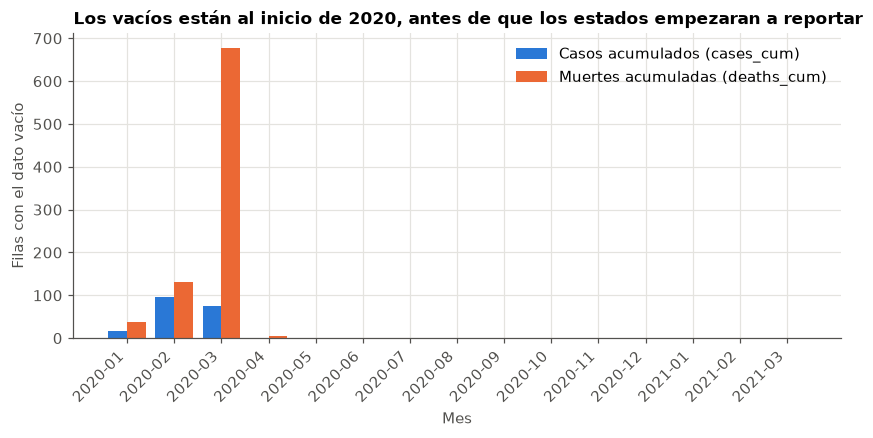

In [10]:
nulos = (df.assign(mes=df["date"].dt.to_period("M").astype(str))
           .groupby("mes")[["cases_cum", "deaths_cum"]].apply(lambda g: g.isna().sum()))

fig, ax = plt.subplots(figsize=(9, 3.6))
x, w = np.arange(len(nulos)), 0.4
ax.bar(x - w / 2, nulos["cases_cum"], w, color=AZUL, label="Casos acumulados (cases_cum)")
ax.bar(x + w / 2, nulos["deaths_cum"], w, color=NARANJA, label="Muertes acumuladas (deaths_cum)")
ax.set_xticks(x)
ax.set_xticklabels(nulos.index, rotation=45, ha="right")
ax.set_xlabel("Mes")
ax.set_ylabel("Filas con el dato vacío")
ax.set_title("Los vacíos están al inicio de 2020, antes de que los estados empezaran a reportar")
ax.legend()
plt.show()
guardar(fig, "01_vacios_por_mes.png")

Casi todos los vacíos de `deaths_cum` (el 99,5 %) caen **antes de abril de 2020**: el estado aún no había registrado casos o muertes. Por eso:

- **Hueco en medio de la serie → último valor conocido** (`ffill` dentro de cada estado). Un acumulado no baja ni se inventa: si hoy no se reportó, lo honesto es mantener el anterior. Se hace *por estado* para que un valor de Nueva York nunca “contamine” a Texas (hay un test que lo comprueba).
- **Hueco antes del primer reporte → 0**, solo para casos y muertes: todavía no había ninguno registrado.
- **Ingresos “actuales” (`hosp_now`, `icu_now`, `vent_now`) → NO se rellenan.** Ahí un vacío significa *no reportado*, no *cero*; imputar 0 inventaría una realidad.
- **`tests_cum` inicial → se deja vacío** (166 filas): un estado pudo hacer pruebas antes de reportarlas.

In [11]:
df = clean_data.fill_cumulative_gaps(df)
df[["cases_cum", "deaths_cum", "tests_cum"]].isna().sum().to_frame("vacíos que quedan")

,vacíos que quedan
cases_cum,0
deaths_cum,0
tests_cum,166


### 2.5 Valores imposibles: incrementos diarios negativos

In [12]:
inc = ["new_cases", "new_deaths", "new_tests", "new_hosp"]
display((df[inc] < 0).sum().to_frame("filas con valor negativo"))
df.nsmallest(3, "new_deaths")[["state", "date", "deaths_cum", "new_deaths"]]

,filas con valor negativo
new_cases,24
new_deaths,73
new_tests,49
new_hosp,88


,state,date,deaths_cum,new_deaths
15231,PA,2020-04-23,"1,421",-201
1092,AR,2021-02-28,"5,243",-174
19584,WA,2020-12-11,"2,850",-166


Los incrementos coinciden **exactamente** con la diferencia entre acumulados del día anterior y el actual, así que los negativos no son un error de cálculo: son **correcciones que hacen los propios estados** (retiran casos o muertes mal contados). Un día no puede tener “−201 muertes”, y dejarlos rompería medias, sumas y gráficos.

**Decisión:** dejar el incremento en 0 y **marcar la fila** en `correction_flag` para no perder el rastro. Se pierde un poco de información (la corrección en sí), pero el acumulado original sigue intacto.

In [13]:
df = clean_data.fix_negative_increments(df)
print("Negativos que quedan:", int((df[inc] < 0).sum().sum()), "· filas marcadas como corrección:", int(df["correction_flag"].sum()))

Negativos que quedan: 0 · filas marcadas como corrección: 219


### 2.6 Inconsistencias entre columnas y territorios

In [14]:
df = clean_data.flag_impossible_values(df)
df = clean_data.add_territory_flag(df)
por_estado = df.groupby("state")[["cases_gt_tests", "deaths_gt_cases"]].sum()
display(por_estado[por_estado.sum(axis=1) > 0])
df.loc[df["cases_gt_tests"], ["state", "date", "cases_cum", "tests_cum", "tests_source"]].head(5)

,cases_gt_tests,deaths_gt_cases
state,,
GA,6,0
MI,15,0
WA,38,0


,state,date,cases_cum,tests_cum,tests_source
4076,GA,2020-03-04,2,0,totalTestsViral
4077,GA,2020-03-05,2,0,totalTestsViral
4078,GA,2020-03-06,2,0,totalTestsViral
4079,GA,2020-03-07,6,0,totalTestsViral
4080,GA,2020-03-08,7,0,totalTestsViral


Hay **59 filas con más positivos que pruebas** (Washington, Michigan y Georgia), algo lógicamente imposible. Puede deberse a que casos y pruebas se miden en unidades distintas o con retraso. **No se corrigen** (no hay forma de saber cuál de las dos cifras está mal): se **marcan** en `cases_gt_tests`. Ninguna fila tiene más muertes que casos.

Los **5 territorios** (AS, GU, MP, PR, VI) se marcan en `is_territory`: no tenemos su población en la segunda fuente, así que los dejaremos fuera de las comparaciones por 100.000 habitantes.

### 2.7 Verificación: paso a paso = pipeline

In [15]:
df = df.sort_values(["state", "date"]).reset_index(drop=True)
clean, rep = clean_data.clean_pipeline(raw)
assert clean.equals(df), "El paso a paso no coincide con clean_pipeline"
print(f"✔ El paso a paso coincide con clean_data.clean_pipeline(): {clean.shape[0]:,} filas × {clean.shape[1]} columnas")
print(f"  (de {rep['columns_in']} columnas de entrada; {len(rep['columns_dropped'])} descartadas)")

✔ El paso a paso coincide con clean_data.clean_pipeline(): 20,780 filas × 32 columnas
  (de 56 columnas de entrada; 28 descartadas)


## 3. Segunda fuente (población) y variables nuevas

Comparar **totales** entre estados es injusto: California tiene 40 millones de habitantes y Vermont 0,6. Para comparar con justicia unimos la **población de cada estado** (Census 2019, `data/external/population_2019.csv`) y normalizamos **por cada 100.000 habitantes**.

In [16]:
poblacion = pd.read_csv(ROOT / "data" / "external" / "population_2019.csv")
print(f"{len(poblacion)} filas (50 estados + DC) · suma = {poblacion['population'].sum():,} (total oficial del Census 2019: 328.239.523)")

df = build_features.add_features(build_features.add_population(clean, poblacion))
nuevas = ["year_month", "week", "weekday", "period", "cfr", "new_cases_7d", "positivity_7d",
          "cases_per_100k", "deaths_per_100k", "new_cases_per_100k_7d", "pop_group"]
fila = df.loc[(df["state"] == "NY") & (df["date"] == "2020-04-15"), nuevas].iloc[0]
fila.to_frame("Nueva York · 15-abr-2020")

51 filas (50 estados + DC) · suma = 328,239,523 (total oficial del Census 2019: 328.239.523)


,Nueva York · 15-abr-2020
year_month,2020-04
week,16
weekday,Wednesday
period,Primavera 2020
cfr,5.42
new_cases_7d,"9,209"
positivity_7d,40.07
cases_per_100k,"1,098.92"
deaths_per_100k,59.56
new_cases_per_100k_7d,47.34


Variables nuevas (*feature engineering*) y para qué sirve cada una:

| Variable | Cómo se calcula | Para qué |
|---|---|---|
| `year_month`, `week`, `weekday` | partes de la fecha | agrupar por mes y detectar efecto del día de la semana |
| `period` | Pre-brote / Primavera 2020 / Verano 2020 / Invierno 2020-21 | comparar etapas de la pandemia |
| `cfr` | muertes ÷ casos × 100 | letalidad **aparente** (depende de cuánto se testea) |
| `new_cases_7d`, `new_deaths_7d` | media móvil de 7 días por estado | quitar el ruido del día de la semana |
| `positivity_7d` | casos de 7 días ÷ pruebas de 7 días × 100 | cuánto del testeo da positivo |
| `cases_per_100k`, `deaths_per_100k` | acumulado ÷ población × 100.000 | comparar estados de distinto tamaño |
| `pop_group` | cuartiles de población | Pequeño / Mediano / Grande / Muy grande |

In [17]:
estados = df[~df["is_territory"]].copy()   # 50 estados + DC (con población)
sobre100 = build_features.positivity_7d(df, cap=False) > 100
print(f"Positividad imposible (>100 %): {int(sobre100.sum())} filas en {sorted(df.loc[sobre100, 'state'].unique())} → se convierten en vacío")
print(f"Filas de estados + DC: {len(estados):,} · de territorios (excluidos de los análisis per cápita): {int(df['is_territory'].sum()):,}")

ultimo = build_features.state_summary(estados).set_index("state")        # situación al 7-mar-2021
ultimo["tests_100k"] = ultimo["tests_cum"] / ultimo["population"] * 1e5
print("Fecha de cierre:", ultimo["date"].max().date())

Positividad imposible (>100 %): 16 filas en ['MI', 'MP', 'WA'] → se convierten en vacío
Filas de estados + DC: 18,995 · de territorios (excluidos de los análisis per cápita): 1,785
Fecha de cierre: 2021-03-07


Una **positividad mayor de 100 %** significa que en esa semana hubo más casos nuevos que pruebas nuevas: es imposible. La variable derivada `positivity_7d` la deja vacía; las columnas originales no se tocan.

## 4. Análisis univariado

Cuatro variables, una a una: casos diarios (histograma), muertes por 100.000 (boxplot), letalidad (histograma) y tipo de prueba (conteo).

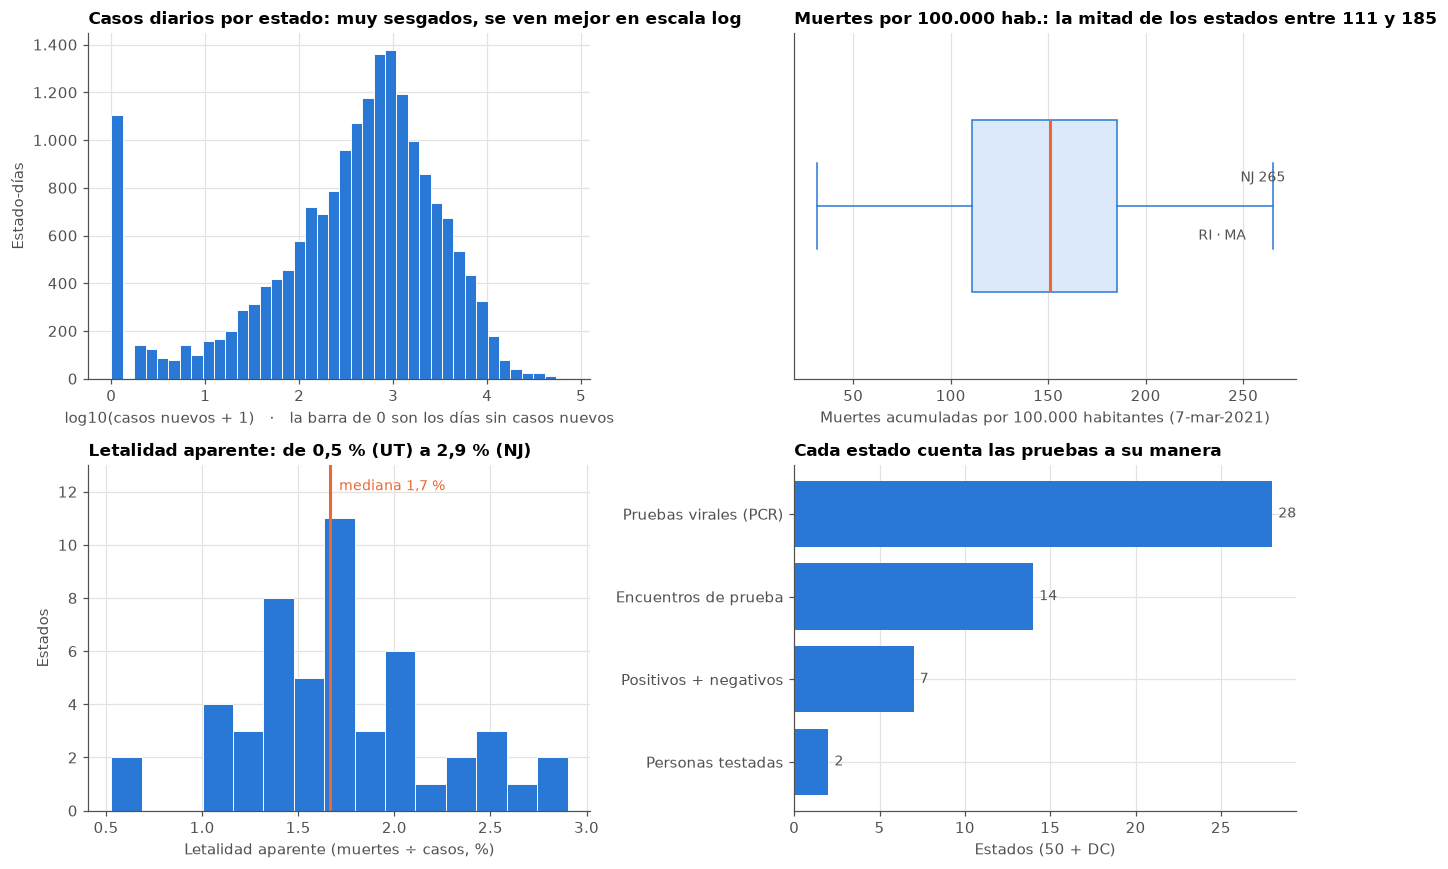

In [18]:
etiquetas_pruebas = {"totalTestsViral": "Pruebas virales (PCR)", "totalTestEncountersViral": "Encuentros de prueba",
                     "posNeg": "Positivos + negativos", "totalTestsPeopleViral": "Personas testadas"}

fig, axs = plt.subplots(2, 2, figsize=(12, 8))

# a) casos diarios: muy sesgados → escala logarítmica
ax = axs[0, 0]
ax.hist(np.log10(estados["new_cases"] + 1), bins=40, color=AZUL, edgecolor="white", linewidth=0.6)
ax.set_title("Casos diarios por estado: muy sesgados, se ven mejor en escala log")
ax.set_xlabel("log10(casos nuevos + 1)   ·   la barra de 0 son los días sin casos nuevos")
ax.set_ylabel("Estado-días")
miles(ax)

# b) muertes por 100.000
ax = axs[0, 1]
ax.boxplot(ultimo["deaths_per_100k"], vert=False, widths=0.5, patch_artist=True,
           boxprops=dict(facecolor="#dce9fa", edgecolor=AZUL), medianprops=dict(color=NARANJA, linewidth=2),
           whiskerprops=dict(color=AZUL), capprops=dict(color=AZUL), flierprops=dict(markeredgecolor=AZUL))
top3 = ultimo["deaths_per_100k"].nlargest(3)
ax.annotate("NJ " + coma(top3["NJ"], 0), (top3["NJ"], 1), xytext=(8, 16), textcoords="offset points", ha="right", fontsize=9, color=INK2)
ax.annotate("RI · MA", (top3.iloc[1:].mean(), 1), xytext=(0, -22), textcoords="offset points", ha="center", fontsize=9, color=INK2)
ax.set_yticks([])
ax.set_xlabel("Muertes acumuladas por 100.000 habitantes (7-mar-2021)")
ax.set_title("Muertes por 100.000 hab.: la mitad de los estados entre 111 y 185")

# c) letalidad aparente
ax = axs[1, 0]
ax.hist(ultimo["cfr"], bins=15, color=AZUL, edgecolor="white", linewidth=0.6)
ax.axvline(ultimo["cfr"].median(), color=NARANJA, linewidth=2)
ax.set_ylim(0, 13)
ax.annotate(f"mediana {coma(ultimo['cfr'].median())} %", (ultimo["cfr"].median(), 12.2),
            xytext=(6, 0), textcoords="offset points", color=NARANJA, fontsize=9, va="center")
ax.set_xlabel("Letalidad aparente (muertes ÷ casos, %)")
ax.set_ylabel("Estados")
ax.set_title("Letalidad aparente: de 0,5 % (UT) a 2,9 % (NJ)")

# d) conteo del tipo de prueba
ax = axs[1, 1]
conteo = ultimo["tests_source"].map(etiquetas_pruebas).value_counts()
ax.barh(conteo.index[::-1], conteo.values[::-1], color=AZUL)
for i, v in enumerate(conteo.values[::-1]):
    ax.annotate(str(v), (v, i), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color=INK2)
ax.set_xlabel("Estados (50 + DC)")
ax.set_title("Cada estado cuenta las pruebas a su manera")

fig.tight_layout()
plt.show()
guardar(fig, "02_univariado.png")

**Lectura**

- **Casos diarios:** la distribución es extremadamente asimétrica (mediana **530**, media **1.508**, máximo **71.734**; asimetría 6,8). Con logaritmo baja a −0,96 y se puede interpretar: por eso usaremos escala log o medias móviles. La barra aislada en 0 son los días sin casos nuevos (un 5,8 % de las filas).
- **Muertes por 100.000:** mediana **151**; **10 estados superan 200** y **7 están por debajo de 80**. Nueva Jersey queda aislado a la derecha.
- **Letalidad aparente:** mediana 1,7 %, pero de 0,5 % (Utah) a 2,9 % (Nueva Jersey). Una diferencia así más que “mejor o peor atención” suele reflejar **cuánto se testea**: si se detectan más casos leves, el denominador crece.
- **Tipo de prueba:** 28 estados cuentan pruebas virales, 14 “encuentros”, 7 suman positivos + negativos y 2 cuentan personas. **No son la misma unidad**, así que comparar pruebas por habitante entre estados tiene un límite (lo retomamos en P3).

## 5. Valores atípicos (outliers)

Usamos la regla del **rango intercuartílico (IQR)**: atípico es lo que cae fuera de `[Q1 − 1,5·IQR, Q3 + 1,5·IQR]`. Primero la medimos de dos formas: con todos los estados juntos y **dentro de cada estado** (para no confundir “estado grande” con “dato raro”).

In [19]:
cols = ["new_cases", "new_deaths", "new_tests"]
pd.DataFrame({
    "% atípicos (estados juntos)": [build_features.iqr_outliers(estados[c]).mean() * 100 for c in cols],
    "% atípicos (dentro de cada estado)": [estados.groupby("state")[c].transform(build_features.iqr_outliers).mean() * 100 for c in cols],
}, index=cols).round(1)

,% atípicos (estados juntos),% atípicos (dentro de cada estado)
new_cases,11.30,7.10
new_deaths,10.50,7.30
new_tests,9.60,2


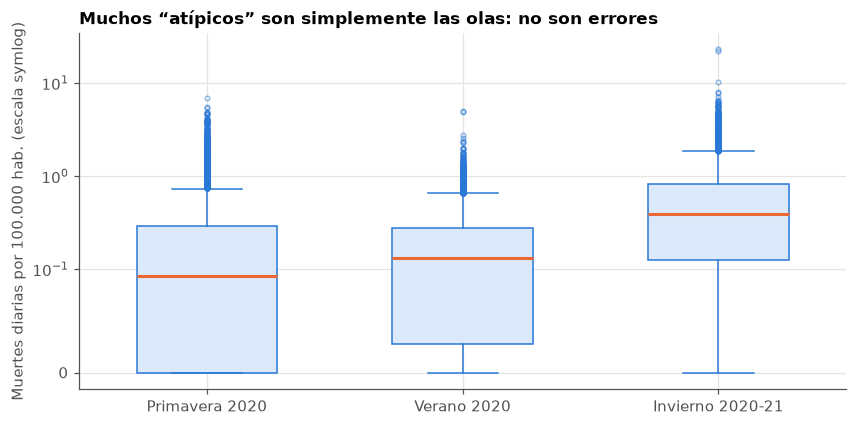

In [20]:
orden = ["Primavera 2020", "Verano 2020", "Invierno 2020-21"]
datos = [estados.loc[estados["period"] == p, "new_deaths"] / estados.loc[estados["period"] == p, "population"] * 1e5 for p in orden]

fig, ax = plt.subplots(figsize=(9, 4.2))
bp = ax.boxplot(datos, tick_labels=orden, patch_artist=True, widths=0.55,
                boxprops=dict(facecolor="#dce9fa", edgecolor=AZUL), medianprops=dict(color=NARANJA, linewidth=2),
                whiskerprops=dict(color=AZUL), capprops=dict(color=AZUL), flierprops=dict(markeredgecolor=AZUL, markersize=3, alpha=0.5))
ax.set_yscale("symlog", linthresh=0.1)
ax.set_ylabel("Muertes diarias por 100.000 hab. (escala symlog)")
ax.set_title("Muchos “atípicos” son simplemente las olas: no son errores")
plt.show()
guardar(fig, "03_atipicos_por_periodo.png")

Entre el **7 % y el 11 %** de los días de casos y muertes son atípicos según IQR (hasta un 2 % en pruebas, si se compara dentro de cada estado). Eso es demasiado para ser “error”: son los **picos de las olas**, que en una pandemia son justamente lo que queremos ver. **Decisión: no eliminarlos.**

Pero dentro de los atípicos hay algunos que sí huelen a **carga de datos atrasados**: días en que un estado reporta **al menos 5 veces su media semanal** (y esa media ya incluye al propio día extremo, así que el salto real es mayor).

In [21]:
razon = estados["new_deaths"] / estados["new_deaths_7d"].where(estados["new_deaths_7d"] >= 5)
picos = estados.assign(veces_su_media=razon.round(1))[(razon >= 5) & (estados["new_deaths"] >= 200)]
picos = picos[["state", "date", "new_deaths", "new_deaths_7d", "veces_su_media"]].copy()
picos["new_deaths_7d"] = picos["new_deaths_7d"].round(0)
display(picos.reset_index(drop=True))

oh = int(estados[(estados["state"] == "OH") & estados["date"].between("2021-02-11", "2021-02-13")]["new_deaths"].sum())
feb = int(estados[estados["date"].between("2021-02-01", "2021-02-28")]["new_deaths"].sum())
print(f"Ohio: {oh:,} muertes en 3 días (11–13-feb-2021) = {oh / feb:.1%} de todas las muertes de febrero en EE. UU. ({feb:,})")

,state,date,new_deaths,new_deaths_7d,veces_su_media
0,GA,2020-11-03,480,91,5.30
1,IN,2021-02-04,1546,251,6.20
2,MO,2021-02-02,340,57,5.90
3,MO,2021-02-11,270,45,6
4,MO,2021-02-18,225,38,6
5,MO,2021-03-03,216,36,5.90
6,OH,2021-02-12,2559,509,5
7,OH,2021-03-05,467,90,5.20


Ohio: 4,484 muertes en 3 días (11–13-feb-2021) = 6.3% de todas las muertes de febrero en EE. UU. (71,032)


**Decisión:** los valores de Ohio, Indiana, Missouri y Georgia **se conservan** (son lo que dice la fuente y el acumulado final es correcto), pero:

- en gráficos de tendencia usamos **medias de 7 días** para que un día así no domine la curva;
- se avisa en el informe de calidad: **estos picos reflejan cuándo se reportó, no cuándo murió la gente**. El propio dataset no confirma la causa (probable carga atrasada o reclasificación).

## 6. Análisis bivariado

Relaciones entre dos variables, un punto por estado (50 + DC) con datos al 7-mar-2021.

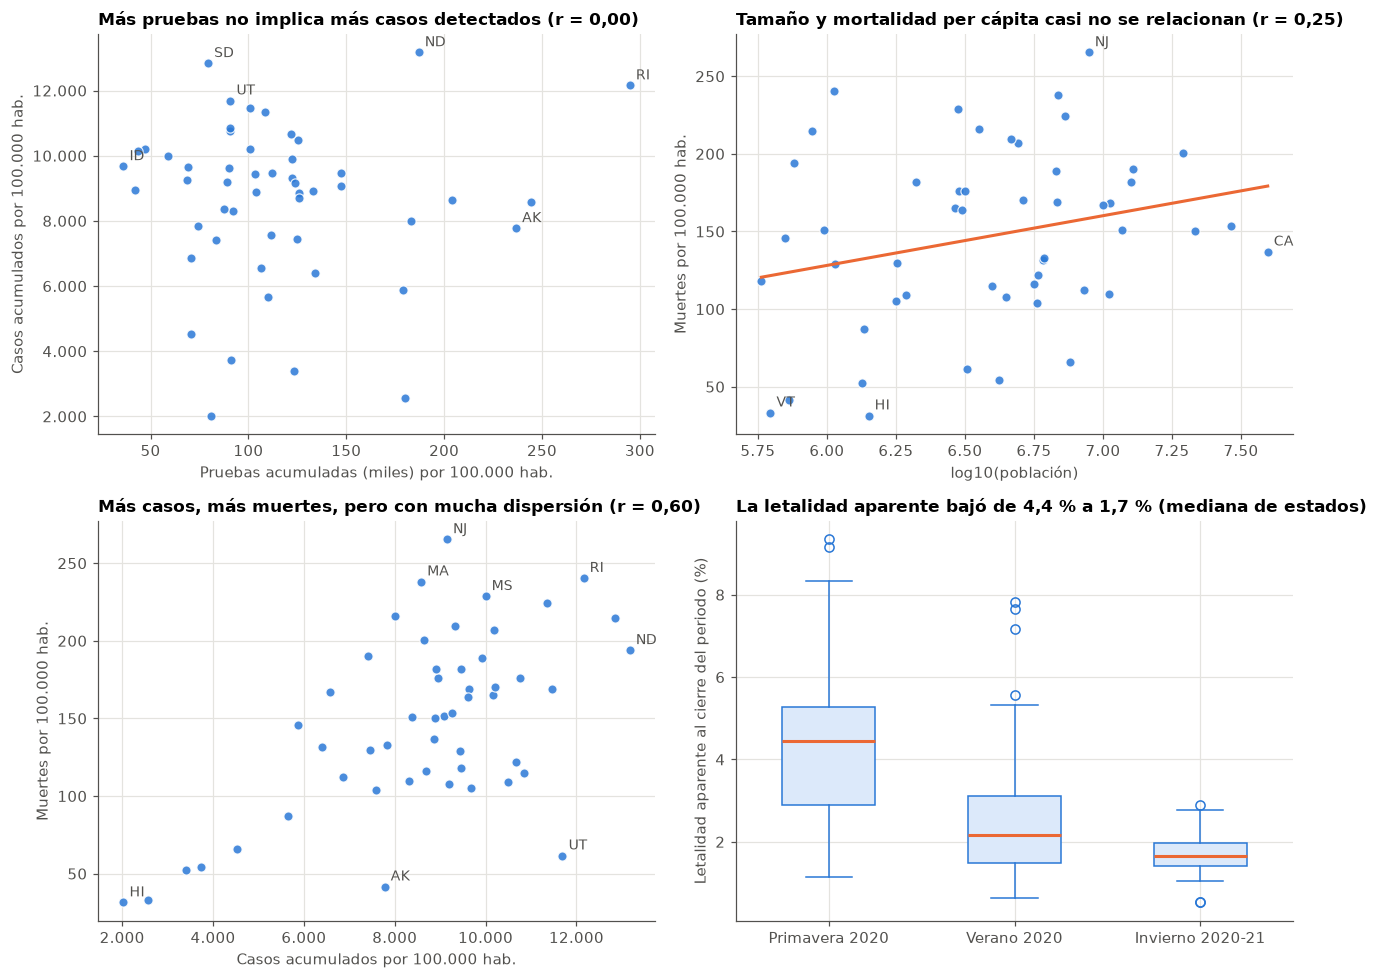

In [22]:
def etiquetar(ax, datos, x, y, estados_a_marcar, dx=4, dy=4):
    for s in estados_a_marcar:
        ax.annotate(s, (datos.loc[s, x], datos.loc[s, y]), xytext=(dx, dy), textcoords="offset points", fontsize=9, color=INK2)

fig, axs = plt.subplots(2, 2, figsize=(12, 9))

# a) pruebas vs casos
ax = axs[0, 0]
r = ultimo["tests_100k"].corr(ultimo["cases_per_100k"])
ax.scatter(ultimo["tests_100k"] / 1000, ultimo["cases_per_100k"], color=AZUL, s=36, alpha=0.85, edgecolor="white", linewidth=0.8)
etiquetar(ax, ultimo.assign(tests_100k=ultimo["tests_100k"] / 1000), "tests_100k", "cases_per_100k", ["RI", "AK", "ND", "SD", "ID", "UT"])
ax.set_xlabel("Pruebas acumuladas (miles) por 100.000 hab.")
ax.set_ylabel("Casos acumulados por 100.000 hab.")
miles(ax)
ax.set_title(f"Más pruebas no implica más casos detectados (r = {coma(r, 2)})")

# b) población vs muertes per cápita
ax = axs[0, 1]
lp = np.log10(ultimo["population"])
r = lp.corr(ultimo["deaths_per_100k"])
ax.scatter(lp, ultimo["deaths_per_100k"], color=AZUL, s=36, alpha=0.85, edgecolor="white", linewidth=0.8)
m, b = np.polyfit(lp, ultimo["deaths_per_100k"], 1)
xs = np.linspace(lp.min(), lp.max(), 50)
ax.plot(xs, m * xs + b, color=NARANJA, linewidth=2)
etiquetar(ax, ultimo.assign(lp=lp), "lp", "deaths_per_100k", ["NJ", "CA", "VT", "HI"])
ax.set_xlabel("log10(población)")
ax.set_ylabel("Muertes por 100.000 hab.")
ax.set_title(f"Tamaño y mortalidad per cápita casi no se relacionan (r = {coma(r, 2)})")

# c) casos vs muertes per cápita
ax = axs[1, 0]
r = ultimo["cases_per_100k"].corr(ultimo["deaths_per_100k"])
ax.scatter(ultimo["cases_per_100k"], ultimo["deaths_per_100k"], color=AZUL, s=36, alpha=0.85, edgecolor="white", linewidth=0.8)
etiquetar(ax, ultimo, "cases_per_100k", "deaths_per_100k", ["NJ", "RI", "MA", "MS", "UT", "AK", "ND", "HI"])
ax.set_xlabel("Casos acumulados por 100.000 hab.")
ax.set_ylabel("Muertes por 100.000 hab.")
miles(ax, "x")
ax.set_title(f"Más casos, más muertes, pero con mucha dispersión (r = {coma(r, 2)})")

# d) letalidad por periodo
ax = axs[1, 1]
fin_periodo = estados.groupby(["period", "state"]).tail(1)
orden = ["Primavera 2020", "Verano 2020", "Invierno 2020-21"]
datos = [fin_periodo.loc[fin_periodo["period"] == p, "cfr"].dropna() for p in orden]
ax.boxplot(datos, tick_labels=orden, patch_artist=True, widths=0.5,
           boxprops=dict(facecolor="#dce9fa", edgecolor=AZUL), medianprops=dict(color=NARANJA, linewidth=2),
           whiskerprops=dict(color=AZUL), capprops=dict(color=AZUL), flierprops=dict(markeredgecolor=AZUL))
ax.set_ylabel("Letalidad aparente al cierre del periodo (%)")
ax.set_title("La letalidad aparente bajó de 4,4 % a 1,7 % (mediana de estados)")

fig.tight_layout()
plt.show()
guardar(fig, "04_bivariado.png")

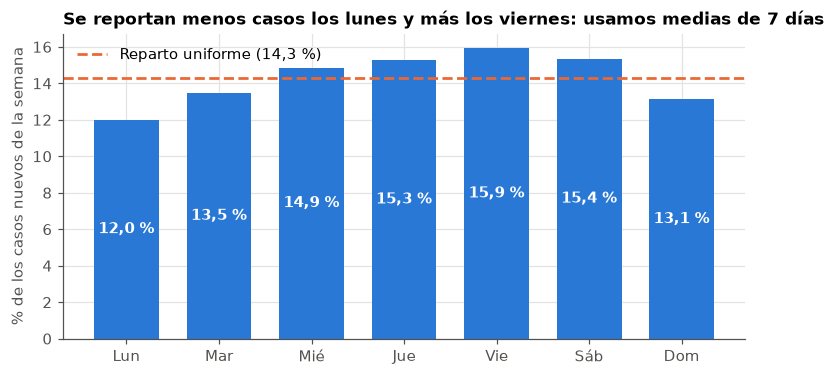

In [23]:
orden_dias = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
nombres = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
peso = estados.groupby("weekday")["new_cases"].sum().reindex(orden_dias)
peso = peso / peso.sum() * 100

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(nombres, peso.values, color=AZUL, width=0.7)
for i, v in enumerate(peso.values):
    ax.annotate(f"{coma(v)} %", (i, v / 2), ha="center", va="center", fontsize=10, color="white", fontweight="bold")
ax.axhline(100 / 7, color=NARANJA, linewidth=1.8, linestyle="--", label="Reparto uniforme (14,3 %)")
ax.legend(loc="upper left")
ax.set_ylabel("% de los casos nuevos de la semana")
ax.set_title("Se reportan menos casos los lunes y más los viernes: usamos medias de 7 días")
plt.show()
guardar(fig, "05_dia_de_la_semana.png")

**Lectura de las cuatro relaciones**

1. **Pruebas ↔ casos (r ≈ 0,00).** En contra de la intuición, no hay relación entre cuánto testeó un estado y cuántos casos por habitante detectó. Parte de la explicación es que **cada estado mide “prueba” de forma distinta** (sección 4), así que esa variable no es del todo comparable. Es un resultado a tomar con cautela, no una prueba de que testear no importe.
2. **Población ↔ muertes per cápita (r ≈ 0,25).** El tamaño del estado explica muy poco. California (rank 29 de 51 per cápita) y Nueva Jersey están en extremos opuestos con tamaños muy distintos.
3. **Casos ↔ muertes (r ≈ 0,60).** Relación positiva y razonable, pero con mucha dispersión: a igual tasa de casos hay estados con el doble de muertes.
4. **Letalidad por periodo.** La mediana cae de **4,4 %** (primavera) a **2,2 %** (verano) y **1,7 %** (invierno). Es una letalidad *aparente*: baja en parte porque se testeó mucho más y se detectaron casos leves, no solo porque se tratara mejor.

**Día de la semana:** el lunes concentra solo el 12,0 % de los casos y el viernes el 15,9 %. Es un efecto de **cuándo se reporta**, no de cuándo se contagia la gente. Otro motivo para suavizar con media de 7 días.

## 7. Agrupar y resumir (`groupby`, `agg`, `pivot_table`)

### Resumen nacional por periodo

In [24]:
nat = build_features.national_daily(df)             # suma de 50 estados + DC por día
nat["period"] = build_features.assign_period(nat["date"])
orden_p = ["Pre-brote", "Primavera 2020", "Verano 2020", "Invierno 2020-21"]
resumen = (nat.groupby("period")
              .agg(casos=("new_cases", "sum"), muertes=("new_deaths", "sum"),
                   pico_casos_7d=("new_cases_7d", "max"), pico_muertes_7d=("new_deaths_7d", "max"))
              .reindex(orden_p))
resumen["% de los casos"] = resumen["casos"] / resumen["casos"].sum() * 100
resumen["% de las muertes"] = resumen["muertes"] / resumen["muertes"].sum() * 100
resumen.round(1)

,casos,muertes,pico_casos_7d,pico_muertes_7d,% de los casos,% de las muertes
period,,,,,,
Pre-brote,18,5,1.60,0.70,0,0
Primavera 2020,1789798,100854,"31,063.70","2,112.10",6.20,19.60
Verano 2020,5363822,97861,"66,341","1,142.10",18.70,19
Invierno 2020-21,21499032,315252,"246,418.90","3,333.90",75,61.30


### Muertes diarias per cápita: periodo × tamaño del estado (tabla dinámica)

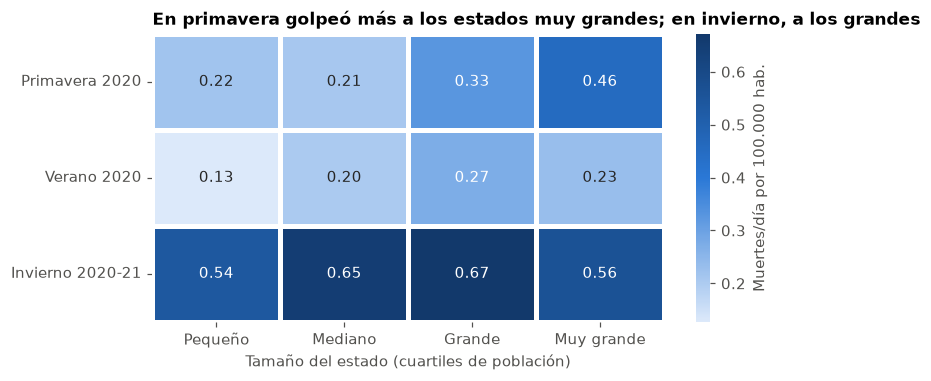

In [25]:
orden_g = ["Pequeño", "Mediano", "Grande", "Muy grande"]
pivot = pd.pivot_table(estados, index="period", columns="pop_group", values="new_deaths_per_100k_7d", aggfunc="mean")
pivot = pivot.reindex(orden_p)[orden_g]

fig, ax = plt.subplots(figsize=(7.5, 3.4))
sns.heatmap(pivot.drop("Pre-brote"), annot=True, fmt=".2f", cmap=SEQ, linewidths=2, linecolor="white",
            cbar_kws={"label": "Muertes/día por 100.000 hab."}, ax=ax)
ax.set_xlabel("Tamaño del estado (cuartiles de población)")
ax.set_ylabel("")
ax.set_title("En primavera golpeó más a los estados muy grandes; en invierno, a los grandes")
plt.show()
guardar(fig, "06_pivot_periodo_tamano.png")

**Lectura.** Las **muertes diarias per cápita crecieron en cada ola**: de 0,30 (primavera) a 0,60 (invierno) en promedio. En primavera los estados **muy grandes** (0,46) estaban más golpeados que los pequeños (0,22); en invierno la diferencia casi desaparece (pequeños 0,54, muy grandes 0,56) y los más afectados son los **grandes** (0,67). Es decir, **la pandemia fue “llegando” a todos los estados**.

### Evolución mensual por tamaño de estado

In [26]:
mensual = pd.pivot_table(estados, index="year_month", columns="pop_group", values="new_cases_per_100k_7d", aggfunc="mean")[orden_g]
mensual.round(1).tail(8)

pop_group,Pequeño,Mediano,Grande,Muy grande
year_month,,,,
2020-08,10,14.60,15.90,13.20
2020-09,13.20,15.30,14.70,10.20
2020-10,29.20,24.30,22.30,13.80
2020-11,62.70,59.30,53.50,38.30
2020-12,53.80,64.50,65,55
2021-01,41.10,59.10,59,58.40
2021-02,20.10,25.50,25.60,29.40
2021-03,16.70,15.90,16.40,20.90


## 8. Matriz de correlación

Sobre los 51 estados (50 + DC) con variables ya normalizadas por población: tasas, picos y hospitalizaciones.

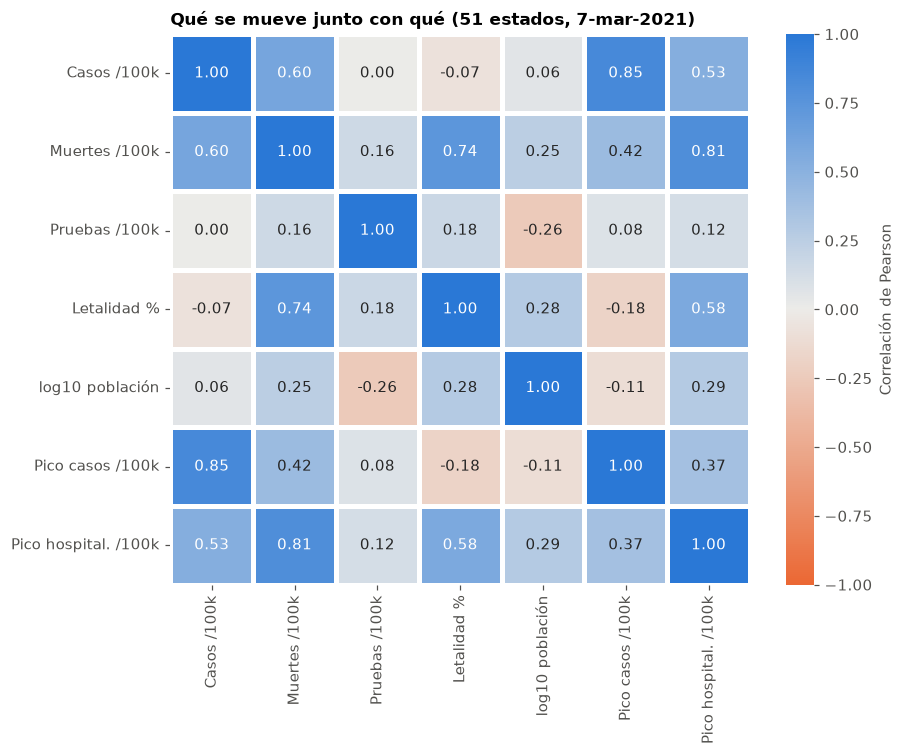

In [27]:
est = ultimo.copy()
est["pico_casos_100k"] = est["peak_new_cases_7d"] / est["population"] * 1e5
est["pico_hosp_100k"] = estados.groupby("state")["hosp_now"].max() / est["population"] * 1e5
est["log_poblacion"] = np.log10(est["population"])

nombres_corr = {"cases_per_100k": "Casos /100k", "deaths_per_100k": "Muertes /100k", "tests_100k": "Pruebas /100k",
                "cfr": "Letalidad %", "log_poblacion": "log10 población",
                "pico_casos_100k": "Pico casos /100k", "pico_hosp_100k": "Pico hospital. /100k"}
corr = est[list(nombres_corr)].rename(columns=nombres_corr).corr()

fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=DIV, vmin=-1, vmax=1, center=0, linewidths=2, linecolor="white",
            cbar_kws={"label": "Correlación de Pearson"}, ax=ax)
ax.set_title("Qué se mueve junto con qué (51 estados, 7-mar-2021)")
plt.show()
guardar(fig, "07_correlaciones.png")

**Interpretación**

- **Muertes ↔ pico de hospitalizados (0,81)** es la relación más fuerte con la mortalidad: donde los hospitales se llenaron más, murió más gente por habitante.
- **Muertes ↔ letalidad (0,74)** es en parte mecánica (las muertes están en el numerador).
- **Casos ↔ pico de casos (0,85)** también es casi evidente: un estado con muchos casos acumulados tuvo un pico alto.
- **Casos ↔ muertes (0,60):** relación moderada, no determinista.
- **Pruebas ↔ casos (0,00) y población ↔ casi todo (|r| ≤ 0,29):** no hay señal clara.

⚠️ **Correlación no es causalidad**, y aquí hay solo **51 puntos** (uno por estado). Sirven para formular hipótesis, no para demostrarlas.

## 9. Tendencias en el tiempo

Dos transformaciones, ambas justificadas:

- **Media móvil de 7 días**, porque los datos diarios tienen un ciclo semanal de reporte (sección 6) y picos por datos atrasados (sección 5).
- **Escala logarítmica** en acumulados, porque crecen de forma casi exponencial al inicio y una escala lineal aplasta todo lo anterior a mayo.

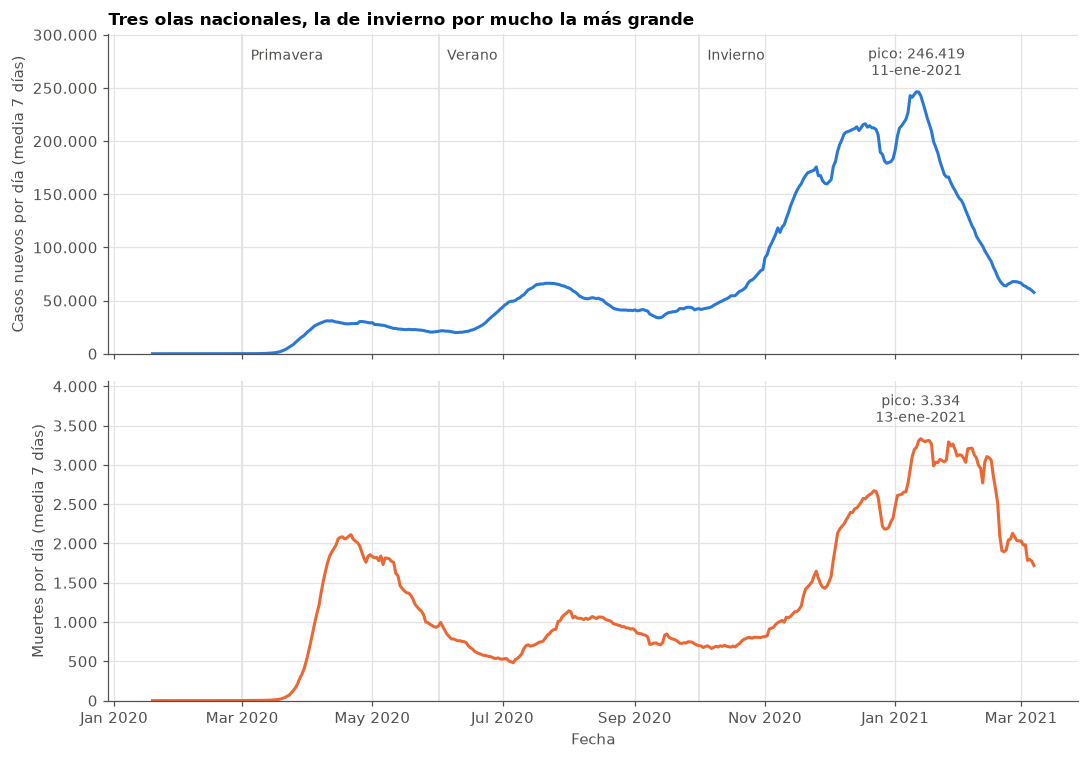

In [28]:
fig, axs = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for ax, col, color, unidad in [(axs[0], "new_cases_7d", AZUL, "Casos nuevos por día"),
                               (axs[1], "new_deaths_7d", NARANJA, "Muertes por día")]:
    ax.plot(nat["date"], nat[col], color=color, linewidth=2)
    i = nat[col].idxmax()
    ax.annotate(f"pico: {nat.loc[i, col]:,.0f}".replace(",", ".") + f"\n{nat.loc[i, 'date'].day}-ene-2021", (nat.loc[i, "date"], nat.loc[i, col]),
                xytext=(0, 8), textcoords="offset points", ha="center", va="bottom", fontsize=9, color=INK2)
    for fecha in ["2020-03-01", "2020-06-01", "2020-10-01"]:
        ax.axvline(pd.Timestamp(fecha), color=GRID, linewidth=1.2, zorder=0)
    ax.set_ylabel(unidad + " (media 7 días)")
    ax.set_ylim(0, nat[col].max() * 1.22)
    miles(ax)
axs[0].set_title("Tres olas nacionales, la de invierno por mucho la más grande")
for texto, fecha in [("Primavera", "2020-03-05"), ("Verano", "2020-06-05"), ("Invierno", "2020-10-05")]:
    axs[0].annotate(texto, (pd.Timestamp(fecha), axs[0].get_ylim()[1] * 0.92), fontsize=9, color=INK2)
axs[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
axs[1].set_xlabel("Fecha")
fig.tight_layout()
plt.show()
guardar(fig, "08_tendencia_nacional.png")

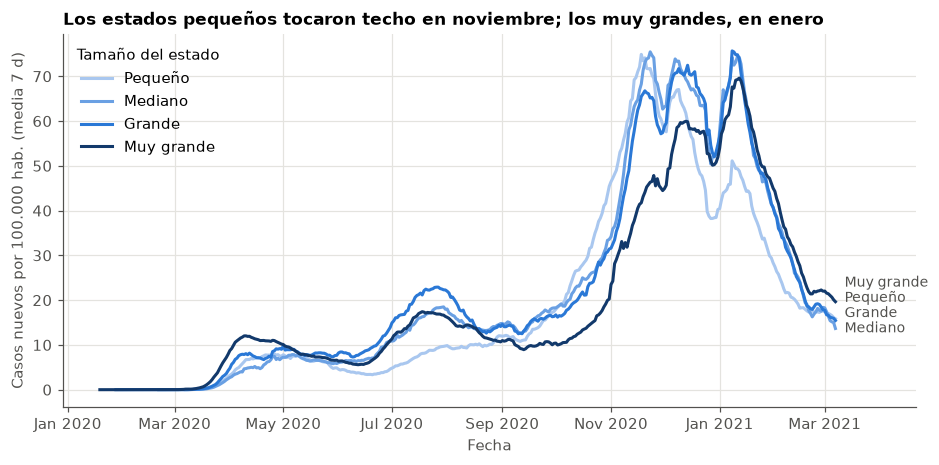

In [29]:
serie = (estados.groupby(["date", "pop_group"])["new_cases_per_100k_7d"].mean().unstack()[orden_g])

# el título afirma esto: lo comprobamos para que el texto no se desincronice de los datos
assert serie["Pequeño"].idxmax().month == 11 and serie["Muy grande"].idxmax().month == 1

fig, ax = plt.subplots(figsize=(10, 4.4))
for g, c in zip(orden_g, AZULES4):
    ax.plot(serie.index, serie[g], color=c, linewidth=2, label=g)
etiquetas_finales(ax, [serie.index[-1]] * 4, [serie[g].iloc[-1] for g in orden_g], orden_g, hueco=3.4)
ax.set_xlim(right=serie.index[-1] + pd.Timedelta(days=45))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_ylabel("Casos nuevos por 100.000 hab. (media 7 d)")
ax.set_xlabel("Fecha")
ax.set_title("Los estados pequeños tocaron techo en noviembre; los muy grandes, en enero")
ax.legend(loc="upper left", title="Tamaño del estado")
plt.show()
guardar(fig, "09_tendencia_por_tamano.png")

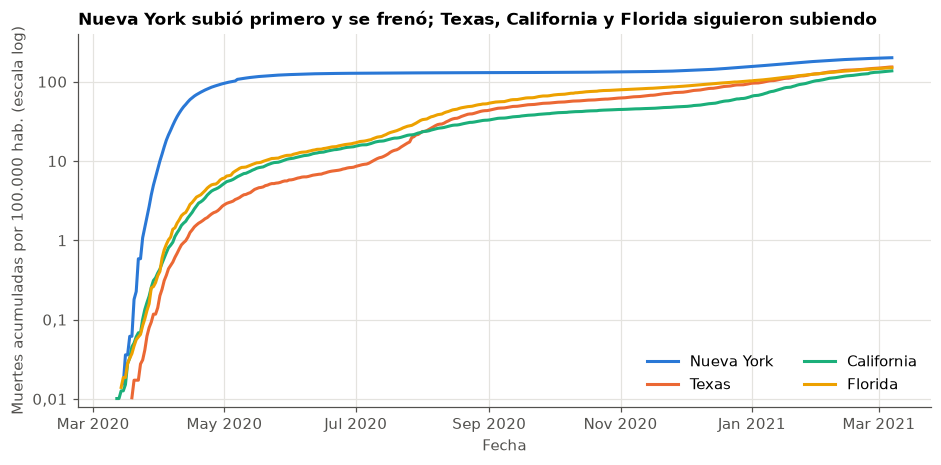

In [30]:
grandes = {"NY": ("Nueva York", AZUL), "TX": ("Texas", NARANJA), "CA": ("California", AGUA), "FL": ("Florida", AMARILLO)}
fig, ax = plt.subplots(figsize=(10, 4.4))
for s, (nombre, c) in grandes.items():
    d = estados[(estados["state"] == s) & (estados["deaths_per_100k"] > 0.01)]
    ax.plot(d["date"], d["deaths_per_100k"], color=c, linewidth=2, label=nombre)
ax.set_yscale("log")
ax.set_ylim(0.008, 400)
ax.set_yticks([0.01, 0.1, 1, 10, 100])
ax.set_yticklabels(["0,01", "0,1", "1", "10", "100"])
ax.minorticks_off()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_ylabel("Muertes acumuladas por 100.000 hab. (escala log)")
ax.set_xlabel("Fecha")
ax.set_title("Nueva York subió primero y se frenó; Texas, California y Florida siguieron subiendo")
ax.legend(loc="lower right", ncol=2)
plt.show()
guardar(fig, "10_log_acumuladas.png")

**Lectura.** A nivel nacional hay **tres olas claras** y la de invierno es varias veces mayor que las otras dos. En escala log, **Nueva York** aparece primero con una pendiente casi vertical en marzo de 2020 y luego se aplana, mientras que Texas, California y Florida crecen más tarde y de forma sostenida: la pandemia **no fue una sola curva sino muchas, en momentos distintos**.

## 10. Comparar segmentos: ¿quién sufrió más, de forma justa?

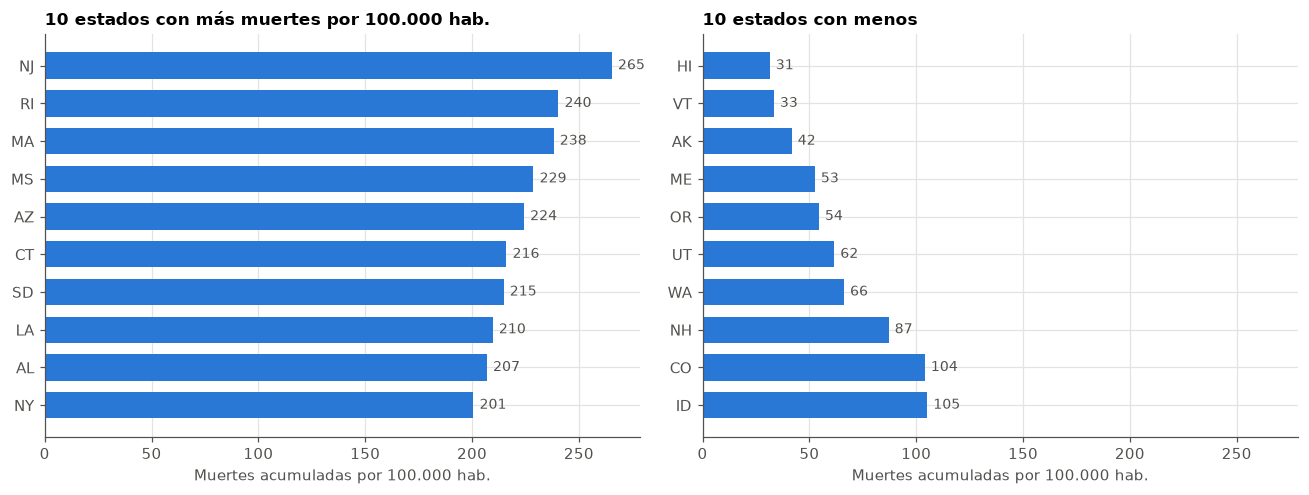

Mayores totales absolutos: {'CA': 54124, 'TX': 44451, 'NY': 39029, 'FL': 32266, 'PA': 24349}
California: 54,124 muertes en total, pero 137 por 100.000 (puesto 29 de 51).


In [31]:
top = ultimo["deaths_per_100k"].nlargest(10)
bajo = ultimo["deaths_per_100k"].nsmallest(10)

fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), sharex=True)
for ax, serie_, titulo in [(axs[0], top, "10 estados con más muertes por 100.000 hab."),
                           (axs[1], bajo, "10 estados con menos")]:
    ax.barh(serie_.index[::-1], serie_.values[::-1], color=AZUL, height=0.7)
    for i, v in enumerate(serie_.values[::-1]):
        ax.annotate(f"{v:.0f}", (v, i), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color=INK2)
    ax.set_title(titulo)
    ax.set_xlabel("Muertes acumuladas por 100.000 hab.")
fig.tight_layout()
plt.show()
guardar(fig, "11_top_bottom.png")

abs_ = ultimo["deaths_cum"].nlargest(5).astype(int).to_dict()
print("Mayores totales absolutos:", abs_)
print(f"California: {int(ultimo.loc['CA', 'deaths_cum']):,} muertes en total, pero {ultimo.loc['CA', 'deaths_per_100k']:.0f} por 100.000 (puesto {int(ultimo['deaths_per_100k'].rank(ascending=False)['CA'])} de 51).")

Peor mes en primavera: ['CT', 'DC', 'LA', 'MA', 'MD', 'MI', 'NJ', 'NY', 'RI']
Peor mes entre noviembre y febrero: 42 de 51 · en verano/otoño temprano: 0


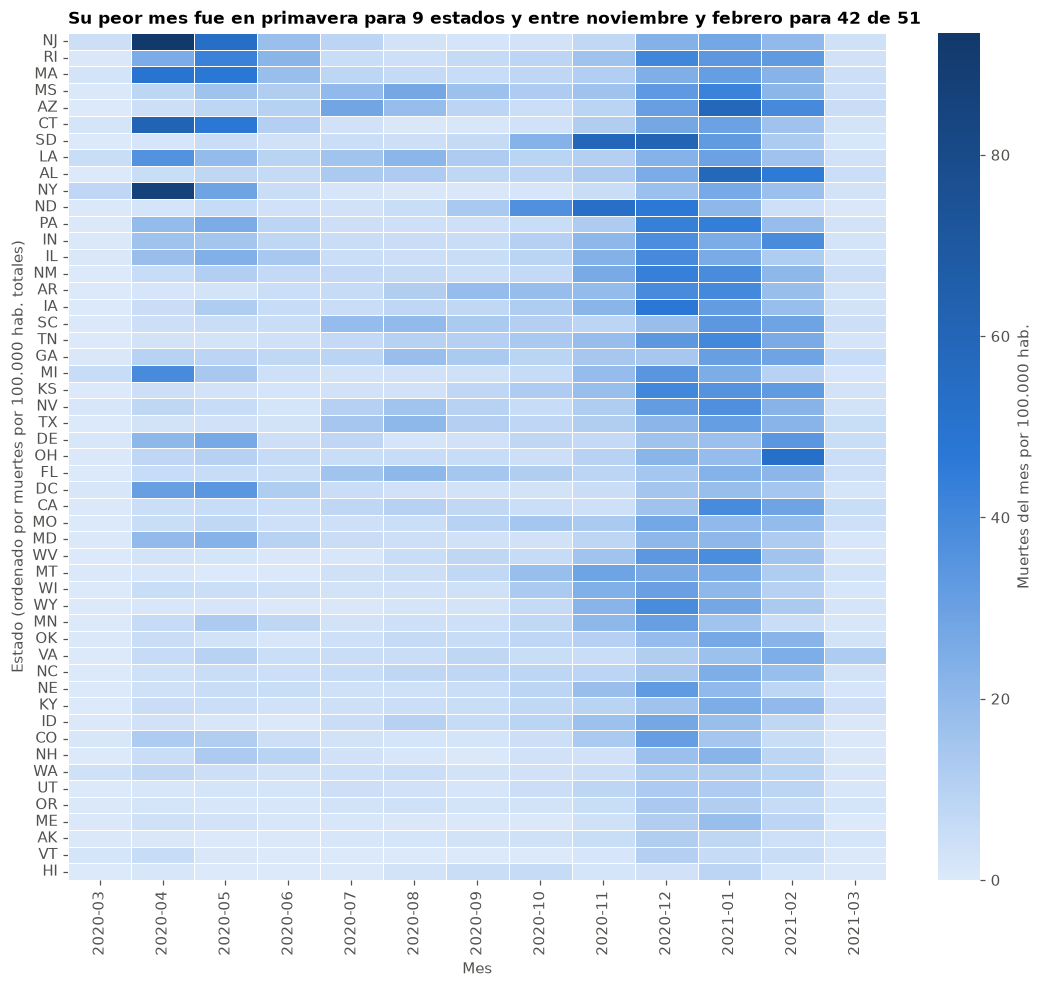

In [32]:
m = (estados.groupby(["state", "year_month"])["new_deaths"].sum().unstack(fill_value=0))
m = m.div(ultimo["population"], axis=0) * 1e5
m = m.loc[ultimo["deaths_per_100k"].sort_values(ascending=False).index]
m = m.loc[:, m.columns >= "2020-03"]

peor_mes = m.idxmax(axis=1)
n_prim = int((peor_mes <= "2020-05").sum())
n_inv = int(((peor_mes >= "2020-11") & (peor_mes <= "2021-02")).sum())
print("Peor mes en primavera:", sorted(peor_mes[peor_mes <= "2020-05"].index))
print(f"Peor mes entre noviembre y febrero: {n_inv} de {len(peor_mes)} · en verano/otoño temprano: {len(peor_mes) - n_prim - n_inv}")

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(m, cmap=SEQ, linewidths=0.5, linecolor="white", cbar_kws={"label": "Muertes del mes por 100.000 hab."}, ax=ax)
ax.set_xlabel("Mes")
ax.set_ylabel("Estado (ordenado por muertes por 100.000 hab. totales)")
ax.set_title(f"Su peor mes fue en primavera para {n_prim} estados y entre noviembre y febrero para {n_inv} de {len(peor_mes)}")
plt.show()
guardar(fig, "12_heatmap_estado_mes.png")

**Lectura.** Con totales absolutos el ranking lo encabezan California, Texas, Nueva York, Florida y Pensilvania: básicamente **los estados más poblados**. Por habitante, el orden cambia por completo: **Nueva Jersey (265), Rhode Island (240), Massachusetts (238), Mississippi (229), Arizona (224) y Connecticut (216)**. En el otro extremo, **Hawái (31), Vermont (33), Alaska (42), Maine (53), Oregón (54) y Utah (62)**. En el mapa de calor se ve el momento de cada estado: **9 estados** (NJ, NY, MA, CT, RI, MD, DC, MI y LA) tuvieron su peor mes en la primavera de 2020 y **42 de los 51** lo tuvieron entre noviembre y febrero; ninguno en verano.

## 11. Gráficos interactivos con Plotly

Los mismos hallazgos, pero explorables: pasa el ratón para ver valores, haz clic en la leyenda para ocultar estados y usa el deslizador del mapa para recorrer los meses. *(Requieren `plotly`, incluido en `requirements.txt`.)*

In [33]:
import plotly.express as px

sel = ["NY", "NJ", "TX", "CA", "FL", "ND"]
fig = px.line(
    estados[estados["state"].isin(sel)], x="date", y="new_cases_per_100k_7d", color="state",
    labels={"date": "Fecha", "new_cases_per_100k_7d": "Casos nuevos por 100.000 hab. (media 7 d)", "state": "Estado"},
    title="Casos nuevos por 100.000 habitantes: cada estado tuvo su propia curva",
)
fig.update_layout(hovermode="x unified", template="simple_white")
fig.show()

In [34]:
mapa = ultimo.reset_index()
fig = px.choropleth(
    mapa, locations="state", locationmode="USA-states", color="deaths_per_100k", scope="usa",
    color_continuous_scale="Blues", hover_name="state_name",
    hover_data={"state": False, "deaths_per_100k": ":.0f", "cases_per_100k": ":.0f", "cfr": ":.1f"},
    labels={"deaths_per_100k": "Muertes /100k", "cases_per_100k": "Casos /100k", "cfr": "Letalidad %"},
    title="Muertes por 100.000 habitantes al 7-mar-2021",
)
fig.show()

In [35]:
mes = (estados.groupby(["year_month", "state"])
              .agg(muertes=("new_deaths", "sum"), population=("population", "first"), state_name=("state_name", "first"))
              .reset_index())
mes["muertes_100k"] = mes["muertes"] / mes["population"] * 1e5
mes = mes[mes["year_month"] >= "2020-03"].sort_values("year_month")

fig = px.choropleth(
    mes, locations="state", locationmode="USA-states", color="muertes_100k", scope="usa",
    animation_frame="year_month", hover_name="state_name", color_continuous_scale="Blues",
    range_color=(0, mes["muertes_100k"].quantile(0.99)),
    labels={"muertes_100k": "Muertes del mes /100k"},
    title="Muertes del mes por 100.000 habitantes (usa el deslizador)",
)
fig.show()

## 12. Respuestas a nuestras preguntas

**P1. ¿Cuándo fueron los peores momentos y cuánto se parecieron?**
Hubo **tres olas** muy distintas en tamaño. Con media de 7 días: *primavera* (casos 12-abr-2020, 31.064/día; muertes 21-abr, 2.112/día), *verano* (casos 23-jul, 66.341/día; muertes 1-ago, 1.142/día) e *invierno* (casos **11-ene-2021, 246.419/día**; muertes **13-ene, 3.334/día**). El periodo de invierno concentra el **75 %** de los casos y el **61 %** de las muertes de todo el dataset. Los hospitales llegaron a su máximo el 6-ene-2021 (132.046 personas hospitalizadas, sumando los estados que reportan ese dato).

**P2. ¿Quién sufrió más por habitante?**
No los de mayores totales. Por 100.000 habitantes, el más afectado fue **Nueva Jersey (265 muertes)**, seguido por Rhode Island, Massachusetts, Mississippi, Arizona y Connecticut. **California** tiene el mayor total absoluto (54.124 muertes) pero está en el puesto 29 de 51 por habitante (137). En casos, los más altos son Dakota del Norte (13.174), Dakota del Sur (12.840) y Rhode Island (12.156 por 100.000).

**P3. ¿Más pruebas, más casos detectados?**
**No se observa** (r = 0,00 entre pruebas y casos por 100.000). Con cautela: cada estado cuenta “pruebas” de forma distinta (28 pruebas virales, 14 encuentros, 7 positivos+negativos, 2 personas), así que la variable no es perfectamente comparable.

**P4. ¿Cambió la letalidad?**
Sí. La letalidad aparente (mediana de estados) bajó de **4,4 %** (primavera) a **2,2 %** (verano) y **1,7 %** (invierno); a nivel nacional pasó de 5,6 % (fin de mayo) a 1,8 % (7-mar-2021). Entre grupos hay un gradiente pequeño: 1,5 % en estados pequeños y medianos frente a 1,8–1,9 % en los grandes. Este dataset **no permite** decir por qué (más testeo de casos leves, mejores tratamientos, población contagiada más joven...): son hipótesis.

**P5. ¿Qué tan fiables son los datos?**
Suficientemente fiables para las conclusiones de arriba, con matices. Hubo que corregir **1.038 vacíos** en acumulados, **234 incrementos diarios negativos** (219 filas), **59 filas con más positivos que pruebas** y **16 de positividad imposible**. Estos problemas afectan sobre todo a la **serie diaria** (por eso suavizamos); el **acumulado final por habitante**, base de los rankings, apenas se ve afectado. Un caso extremo: Ohio reportó 4.484 muertes en 3 días de febrero de 2021, un 6,3 % de las muertes de ese mes en el país.

## 13. Conclusiones, límites y siguientes pasos

**Lo que contamos al CEO**

1. La pandemia en EE. UU. fue **tres olas, no una**, y la de invierno 2020-21 fue de lejos la mayor (3,7 veces el pico de casos de verano).
2. **Los totales engañan:** hay que comparar por habitante. El estado “peor” depende de si miras el total (California) o la tasa (Nueva Jersey).
3. La letalidad aparente **cayó a menos de la mitad**, aunque este dataset no explica por qué.
4. Los datos diarios tienen **ruido propio** (día de la semana, datos atrasados, correcciones): hay que leerlos suavizados.

**Límites**

- Los datos terminan el **7-mar-2021**: nada sobre vacunas ni olas posteriores.
- La población es de **2019** (estimación) y no cubre territorios.
- Casos y pruebas **no se miden igual** entre estados; la positividad es aproximada.
- Las correlaciones usan **51 puntos** y no demuestran causas.

**Siguientes pasos:** explorar el dashboard (`streamlit run app.py`), revisar `reports/data_quality/informe_calidad_datos.md` y el informe ejecutivo en `reports/informe_ejecutivo.pdf`.